In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys
sys.path.insert(0, './Models')
import xpml,swe # type: ignore
# import module_mass_loss as mml
import seaborn as sns

In [2]:
# constants
au = 1.496e11 #Astronomical Unit (m)
Ggrav = 6.67e-11  #gravitational constant m^3/kg/sec^2
M_sun = 1.9885e30 #Sun mass (kg)
M_e = 5.97237e24 #Earth mass (kg)
R_e   = 6.371e6  #Earth radius (m)
day_s = 60*60*24 # s/day

#planets to use
n_planets = 5000

In [ ]:
#load init params
#importing units: MKS
# Importing from Kama mount takes forever
identifier = '640xp_750-1200K_072525'           #'5000xp_1-12Me_500-1200K'
folder = 'evolution-data/gp-evo/5000_xp_070925'  #5000_xp_500-1200K_071225'
# folder = '../kama_mount/evolution-data/gp-evo/5000_xp' #/{n_planets}_xp
filename = './' + folder + '/5000_xp_gp_data.csv'
# filename = f'./evolution-data/gp-evo/{n_planets}_xp/{n_planets}_xp_gp_data.csv'
planetnum, mp_gp, rp_gp, mcore_gp, rsurf_gp, teq_gp, wmf_gp, grav_gp, H_gp, lambda_gp, sma_gp, period_gp, startype_gp, mstar_gp, lstar_gp = np.loadtxt(filename,skiprows=1,unpack=True)

rsurf_gp = swe.zeng_radius(mp_gp,0.325) #correct for 5000_xp_070925 pop

In [4]:
#make directory to save plots in

saveplot_folder = '640_xp_750-1200K_072525'
location = './plots/' + saveplot_folder
try:
    os.mkdir(location)
    print(f"Directory '{saveplot_folder}' created successfully in {location}.")
except FileExistsError:
    print(f"Directory '{saveplot_folder}' already exists in {location}.")
except Exception as e:
    print(f"An error occurred: {e}")

Directory '640_xp_750-1200K_072525' already exists in ./plots/640_xp_750-1200K_072525.


In [5]:
# Import final mass, radii, wmf of each simulated planet.
# This will take a while
mp_gp = np.array([])
rp_gp = np.array([])
wmf_gp = np.array([])

mp_final = np.array([])
rp_final = np.array([])
wmf_final = np.array([])
for i in range(n_planets):
    p_file = f'./{folder}/planet_{i+1}-{n_planets}_evolution_data.csv' #planet filename /evolution-data/gp-evo
    mp_evolution, rp_evolution, wmf_evolution = np.loadtxt(p_file,usecols=(1,2,3),unpack=True) #radius evolution array 

    
    mp_gp = np.append(mp_gp, mp_evolution[0])
    rp_gp = np.append(rp_gp, rp_evolution[0])
    wmf_gp = np.append(wmf_gp, wmf_evolution[0])
    
    #append final value ; using [-2] in case there's any weird nan values
    mp_final = np.append(mp_final, mp_evolution[-2])
    rp_final = np.append(rp_final, rp_evolution[-2])
    wmf_final = np.append(wmf_final, wmf_evolution[-2])

print('Final datapoints loaded.')

Final datapoints loaded.


## Masks and Math

In [6]:
#Masks isolated by star type
startype_gp = mstar_gp/M_sun > 0.43
T_G = period_gp[startype_gp]
T_M = period_gp[~startype_gp]

Rp_G = rp_final[startype_gp]/R_e
Rp_M = rp_final[~startype_gp]/R_e

In [8]:
sigmasb = 5.670374419e-8 # W⋅m−2⋅K−4 ; Stefan-Boltzmann constant
L_sun = xpml.L_sun

def period_solver_M(mstar,teq):
    Ls = L_sun*0.23*(mstar/M_sun)**2.3
    a = (Ls / (16 * np.pi * sigmasb * teq**4))**(3/2)
    
    T = 365.25 * np.sqrt(M_sun * a / (mstar * au**3))
    return T

def period_solver_G(mstar,teq):
    Ls = L_sun*(mstar/M_sun)**4
    a = (Ls/(16*np.pi*sigmasb*teq**4))**(3/2)
    T = 365.25 * np.sqrt(M_sun * a / (mstar * au**3))
    return T
    
# sbsigma = 5.670374419e-8 # W⋅m−2⋅K−4 ; Stefan-Boltzmann constant
# print(f'{((np.pi*0.23**3)/(mml.Ggrav**2 * sbsigma**3))**(1/4):.7e}')
print('>> Generated Planet:\nStar Mass:',mstar_gp[1]/M_sun,'solar masses,',startype_gp[1])
print('Planet Teq:',teq_gp[1], 'K')
print('solution:',period_solver_M(0.49243*M_sun, 1190),'days')
print('alternate calculated period:', period_gp[1], 'days')

print('\n>> Testing with NEA data:')
days = period_solver_M(0.162*M_sun,438)
print(days,'days')
print('observed period: 3.152')

days = period_solver_G(0.95*M_sun,1898)
print(days,'days')
print('observed period: 1.5')

>> Generated Planet:
Star Mass: 0.20013578073925067 solar masses, False
Planet Teq: 985.029 K
solution: 0.6516848074941644 days
alternate calculated period: 0.38148 days

>> Testing with NEA data:
3.3480352780229756 days
observed period: 3.152
1.0131668605519113 days
observed period: 1.5


In [9]:
# New period:
new_period_G = period_solver_G(mstar_gp[startype_gp], teq_gp[startype_gp])
new_period_M = period_solver_M(mstar_gp[~startype_gp], teq_gp[~startype_gp])
len(Rp_M)
print(T_G)
print(new_period_G)
# print(len(new_period_M))

[4.42909 3.1332  0.70698 ... 2.47209 2.26451 4.28503]
[4.42628475 3.13121938 0.70653452 ... 2.47054466 2.26308677 4.28234282]


In [10]:
#recompile arrays
endrange = 3000
new_period = np.append(new_period_M,new_period_G)
new_final_rp = np.append(rp_final[~startype_gp],rp_final[startype_gp])
new_final_wmf = np.append(wmf_final[~startype_gp],wmf_final[startype_gp])
new_mstar = np.append(mstar_gp[~startype_gp],mstar_gp[startype_gp])

In [11]:
#remove unicorns
unicorn_killer = period_gp > 1
new_unicorn_killer = new_period > 1 #for MG order

unicorns = period_gp <= 1
new_unicorns = new_period <= 1

In [ ]:
#roche lobe line
x = np.linspace(0.01,30,150)
roche_lim = (8*np.pi**2)/(Ggrav*x*86400*R_e)

# plt.plot(x,roche_lim,label='Unicorns',color='thistle',alpha=.5,zorder=500)
# plt.fill_betweenx(roche_lim,[0],x,color='thistle',alpha=0.25)

## Initial Scatterplots

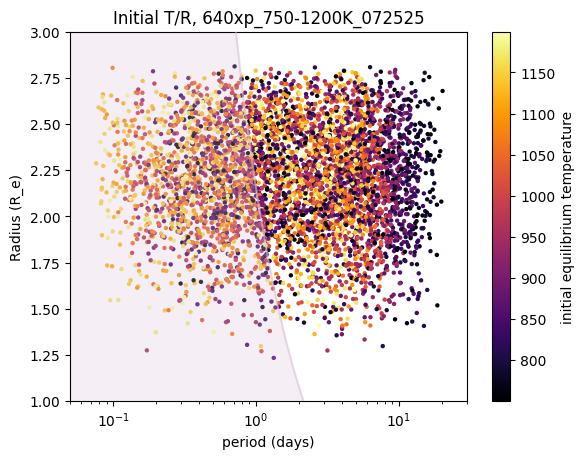

"#- initial M/R -----------\n\nplt.scatter(mp_gp[G_mask]/M_e, rp_gp[G_mask]/R_e, c='orange',edgecolor='none', s=10, alpha=0.5,label='G-star Host')\nplt.scatter(mp_gp[M_mask]/M_e, rp_gp[M_mask]/R_e, c='firebrick',edgecolor='none', s=10, alpha=0.5,label='M-star Host')\n\nplt.axhline(1.8, color='black', linestyle='--', linewidth=1, label='1.8 R_e line')\n\n# plt.colorbar()\nplt.xlabel('Mass (M_e)')\nplt.ylabel('Radius (R_e)')\nplt.xlim(0.5,12.5)\nplt.title('Initial M/R, '+identifier)\nplt.legend(fontsize=8)\n\nplt.savefig(location+'/scatter_mr_initial_startype_'+identifier+'.png',bbox_inches='tight',dpi=600)\nplt.show()"

In [35]:
# Divided by host star

#- initial T/R ------------

# cmap = sns.cm.crestens.
plt.scatter(period_gp, rp_gp, c=teq_gp, cmap='inferno', s=10, edgecolor='none')

# plt.scatter(T_G, rp_gp[G_mask]/R_e, c='orange',edgecolor='none', s=10, alpha=0.5,label='G-star Host')
# plt.scatter(T_M, rp_gp[M_mask]/R_e, c='firebrick',edgecolor='none', s=10, alpha=0.5,label='M-star Host')

#WMF:
# plt.scatter(period_gp, rp_gp/R_e, c=wmf_gp, cmap=cmap, s=10, edgecolor='none')
# plt.colorbar(label='WMF')

#unicorns line
# plt.axvspan(1,0,color='thistle',alpha=0.15,zorder=-100)
# plt.axvline(1,c='thistle',linewidth=1,label='Unicorns',alpha=.5,zorder=500)
plt.plot(x,roche_lim,label='Unicorns',color='thistle',alpha=.5,zorder=500)
plt.fill_betweenx(roche_lim,[0],x,color='thistle',alpha=0.25)

plt.colorbar(label='initial equilibrium temperature')
plt.xlabel('period (days)')
plt.xscale('log')
plt.ylabel('Radius (R_e)')
plt.title('Initial T/R, '+identifier)
plt.xlim(0.05,30)
plt.ylim(1,3)
# plt.legend(fontsize=7)

# plt.savefig(location+'/scatter_tr_initial_teq_'+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()

'''#- initial M/R -----------

plt.scatter(mp_gp[G_mask]/M_e, rp_gp[G_mask]/R_e, c='orange',edgecolor='none', s=10, alpha=0.5,label='G-star Host')
plt.scatter(mp_gp[M_mask]/M_e, rp_gp[M_mask]/R_e, c='firebrick',edgecolor='none', s=10, alpha=0.5,label='M-star Host')

plt.axhline(1.8, color='black', linestyle='--', linewidth=1, label='1.8 R_e line')

# plt.colorbar()
plt.xlabel('Mass (M_e)')
plt.ylabel('Radius (R_e)')
plt.xlim(0.5,12.5)
plt.title('Initial M/R, '+identifier)
plt.legend(fontsize=8)

plt.savefig(location+'/scatter_mr_initial_startype_'+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()'''

## Final Histograms

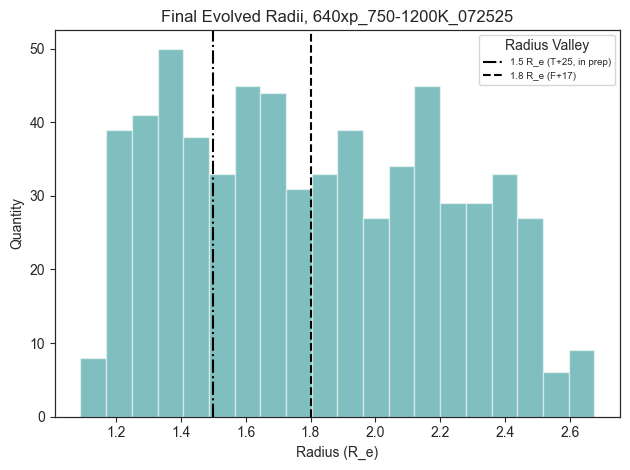

"\n#final radius histograms, unicorns\n\nfig, ax1 = plt.subplots()\n# color = 'tab:blue'\nax1.set(xlabel='Radius (R_e)', ylabel='Quantity')\nax1.hist(rp_final[unicorns]/R_e, bins=25, color='pink')\n\n#second set, kde line sharing x-axis\n# ax2 = ax1.twinx()\n# sns.kdeplot(rp_final[unicorns]/R_e,gridsize=500,color='brown',bw_adjust=.6) #unicornless\n# ax2.tick_params('y', labelleft=False)\n# ax2.set_yticks([])\n# ax2.set_ylabel('')\n\n#add lines, has to be separate to not throw off axis\nax3 = ax1.twinx()\ny_points = [0, 500]\n# ax3.plot([1.3,1.3], y_points, color='black', linestyle=':', label='Super-Earths (Fulton 2017)')\n# ax3.plot([2.4,2.4], y_points, color='black', linestyle='-.', label='Sub-Neptunes (Fulton 2017)')\nax3.plot([1.8,1.8], y_points, color='black', linestyle='--', label='1.8 R_e (F+17)')\nax3.plot([1.5,1.5], y_points, color='black', linestyle='-.', label='1.5 R_e (T+25, in prep)')\nax3.set_ylim(0,350)\nax3.tick_params('y', labelleft=False)\nax3.set_yticks([])\nax3.lege

In [114]:
#final radius histograms, total

fig, ax1 = plt.subplots()
# color = 'tab:blue'
ax1.set(xlabel='Radius (R_e)', ylabel='Quantity')
ax1.hist(rp_final/R_e, bins=20, color='teal', alpha=.5)

# #second set, kde line sharing x-axis
# ax2 = ax1.twinx()
# sns.kdeplot(rp_final/R_e, gridsize=500,color='brown',bw_adjust=.6)
# ax2.tick_params('y', labelleft=False)
# ax2.set_yticks([])
# ax2.set_ylabel('')

#add lines, has to be separate to not throw off axis
ax3 = ax1.twinx()
y_points = [0, 500]
ax3.plot([1.5,1.5], y_points, color='black', linestyle='-.', label='1.5 R_e (T+25, in prep)')
ax3.plot([1.8,1.8], y_points, color='black', linestyle='--', label='1.8 R_e (F+17)')
ax3.set_ylim(0,350)
ax3.tick_params('y', labelleft=False)
ax3.set_yticks([])
ax3.legend(fontsize=7,title='Radius Valley')


plt.title('Final Evolved Radii, ' + identifier)
fig.tight_layout()
plt.savefig(location+'/hist_r_final_' + identifier + '.png',bbox_inches='tight',dpi=600)
plt.show()

'''
#final radius histograms, unicorns

fig, ax1 = plt.subplots()
# color = 'tab:blue'
ax1.set(xlabel='Radius (R_e)', ylabel='Quantity')
ax1.hist(rp_final[unicorns]/R_e, bins=25, color='pink')

#second set, kde line sharing x-axis
# ax2 = ax1.twinx()
# sns.kdeplot(rp_final[unicorns]/R_e,gridsize=500,color='brown',bw_adjust=.6) #unicornless
# ax2.tick_params('y', labelleft=False)
# ax2.set_yticks([])
# ax2.set_ylabel('')

#add lines, has to be separate to not throw off axis
ax3 = ax1.twinx()
y_points = [0, 500]
# ax3.plot([1.3,1.3], y_points, color='black', linestyle=':', label='Super-Earths (Fulton 2017)')
# ax3.plot([2.4,2.4], y_points, color='black', linestyle='-.', label='Sub-Neptunes (Fulton 2017)')
ax3.plot([1.8,1.8], y_points, color='black', linestyle='--', label='1.8 R_e (F+17)')
ax3.plot([1.5,1.5], y_points, color='black', linestyle='-.', label='1.5 R_e (T+25, in prep)')
ax3.set_ylim(0,350)
ax3.tick_params('y', labelleft=False)
ax3.set_yticks([])
ax3.legend(loc='upper right',fontsize=7)


plt.title('Final Evolved Unicorns Radii, ' + identifier)
fig.tight_layout()
plt.savefig(location+'/hist_r_final_unicorns_' + identifier + '.png',bbox_inches='tight',dpi=600)
plt.show()
'''

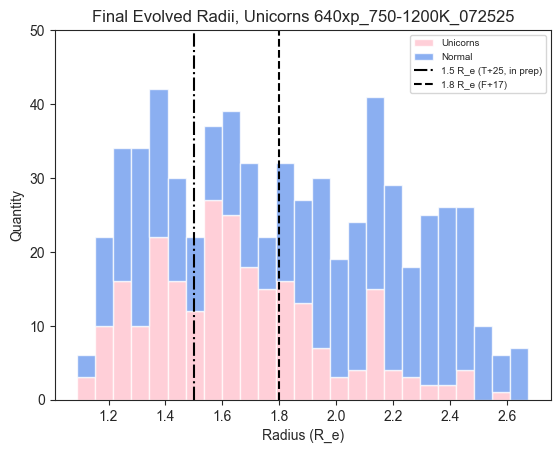

In [102]:
#final stacked histograms

n_bins = 25

#--Unicorns
# Combine data into a list for stacking
stacked_data = [rp_final[unicorns]/R_e, rp_final[unicorn_killer]/R_e]
stacked_type = 'Unicorns '
# Define bin edges and colors
colors = ['pink', 'cornflowerblue']
labels = ['Unicorns', 'Normal']

# #--Star type
# # Combine data into a list for stacking
# stacked_data = [Rp_M, Rp_G]
# stacked_type = 'Star Type'
# # Define bin edges and colors
# colors = ['brown', 'orange']
# labels = ['M Host', 'G Host']


# Create the stacked histogram
plt.hist(stacked_data, bins=25, stacked=True, color=colors, label=labels,alpha=0.75)
plt.vlines(1.5,0,350, color='black',linestyle='-.', label='1.5 R_e (T+25, in prep)')
plt.vlines(1.8,0,350, color='black', linestyle='--', label='1.8 R_e (F+17)')

# Add labels and title
plt.xlabel('Radius (R_e)')
plt.ylabel('Quantity')
plt.ylim(0,50)
plt.title('Final Evolved Radii, '+stacked_type+identifier)
plt.legend(fontsize=7)
fig.tight_layout()
# plt.savefig(location+'/hist_r_final_stacked_unicorns_'+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()

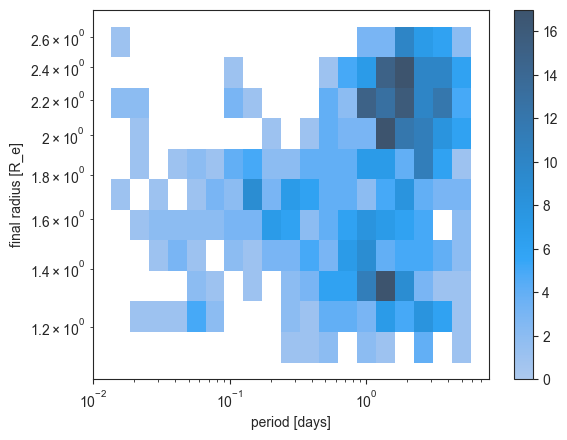

In [103]:
# limited_sep_05 = sma_gp/au < .05
# plt.hist2d(period_gp,rp_final/R_e,bins=100)

sns.histplot(x=period_gp,y=rp_final/R_e,log_scale=True,cbar=True)
plt.xlabel('period [days]')
plt.ylabel('final radius [R_e]')
# plt.colorbar(label='density')
plt.show()

#What the hell :(

## Final Scatterplots

In [48]:
#Radius valley curve equations
# Equation 28, Owen & Wu 2017

# a = (P/365)**(2/3)
# X_HE = 1/(a**2)
# rho_m = 5.51 * 1000/M_e #kg/m^3, density
# R = 1.43 + (eta**0.18 * X_HE**0.19 * rho_m**(-0.24) )/R_e   

eta = 0.1
P = np.linspace(0.2,20,100)
a = au * P**(2/3)
X_HE = M_sun/(a**2)
rho_m = 5.51 * 1000 #kg/m^3, density
# print(P)

R = .5 + 1.25 * P**(-0.25)

#visual line 2
x = np.linspace(0.07,3)
y = 1.53 - 0.03*x


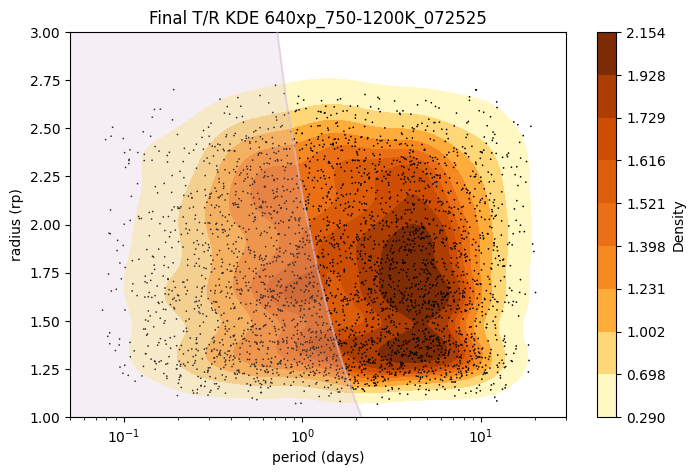

In [38]:
# T/R scatterplot, 2017 survey mimic
plt.figure(figsize=(8,5))

# sns.kdeplot(x=new_period,y=new_final_rp/R_e,cmap='YlOrBr',cbar=True, cbar_kws={'label':'Density'}, fill=True,alpha=1,log_scale=True) #https://ui.adsabs.harvard.edu/abs/2017AJ....154..109F/abstract
# plt.scatter(new_period_G, Rp_G, c='black', s=1.5, edgecolor='none', alpha=0.8, zorder=100) #c=mstar_gp[G_mask], cmap='inferno',
# plt.scatter(new_period_M, Rp_M, c='black', s=1.5, edgecolor='none', alpha=0.8, zorder=100, label='Evolved State')

#unicorn killer
sns.kdeplot(x=period_gp,y=rp_final,cmap='YlOrBr',cbar=True, cbar_kws={'label':'Density'},fill=True,alpha=1,log_scale=True) #https://ui.adsabs.harvard.edu/abs/2017AJ....154..109F/abstract
plt.scatter(period_gp, rp_final, color='black', s=1.5, edgecolor='none')

plt.plot(x,roche_lim,label='Unicorns',color='thistle',alpha=.5,zorder=500)
plt.fill_betweenx(roche_lim,[0],x,color='thistle',alpha=0.25)
plt.xlim(0.05,30)
plt.ylim(1,3)

# #unicorns
# plt.axvspan(1,0,color='thistle',alpha=0.15)
# plt.axvline(1,c='thistle',linewidth=1,label='Unicorns',alpha=.5,zorder=500)

plt.xlabel('period (days)')
plt.ylabel('radius (rp)')
plt.xscale('log')
plt.yscale('linear')
# plt.xlim(0.05,100)
# plt.ylim(.75,3.15)
# plt.grid(color='slategrey',which='both',alpha=0.15)
# plt.legend(loc=(.03,.88),fontsize=8)
plt.title('Final T/R KDE '+identifier)

plt.savefig(location+'/kde_tr_final_'+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()


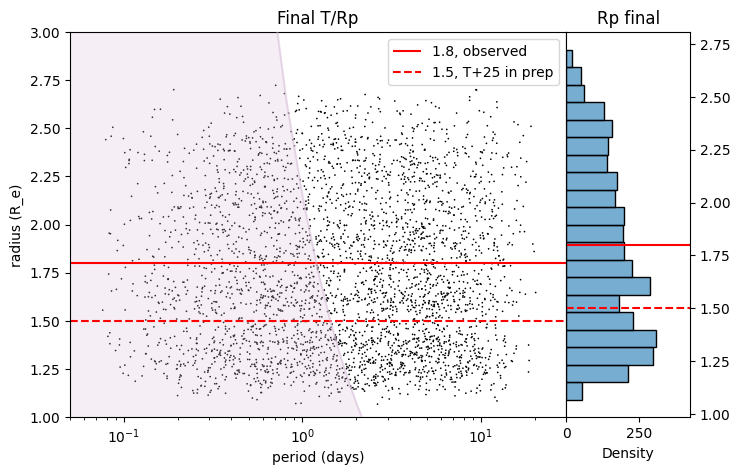

In [41]:
# T/R scatterplot, 2017 survey mimic with extra bit
fig, (ax_scatter, ax_kde) = plt.subplots(1, 2, figsize=(8, 5), gridspec_kw={'width_ratios': [4, 1]})

fig.subplots_adjust(wspace=0)
# Scatterplot: period vs final radius
ax_scatter.scatter(period_gp, rp_final, color='black', s=1.5, edgecolor='none')
ax_scatter.hlines(1.8, 0.05, 80, linestyle='-', color='red', label='1.8, observed')
ax_scatter.hlines(1.5, 0.05, 80, linestyle='--', color='red', label='1.5, T+25 in prep')
ax_scatter.set_xlim(0.05,80)
ax_scatter.set(xlabel='period (days)', ylabel='radius (R_e)', xscale='log', title='Final T/Rp')
ax_scatter.legend()

# KDE plot: final radius
# sns.kdeplot(y=rp_final/R_e, ax=ax_kde, fill=True, levels=25, thresh=0.02, gridsize=100, color='teal', alpha=0.6)
sns.histplot(y=rp_final, ax=ax_kde, bins=20, line_kws={'linewidth':'0'}, alpha=0.6)
ax_kde.set_xlabel('Density')
ax_kde.set_yticks(ax_scatter.get_yticks())
ax_kde.yaxis.tick_right()
ax_kde.tick_params('y', labelleft=False, labelright=True)
ax_kde.set_title('Rp final')
ax_kde.set_xlim(0, 425)
ax_kde.hlines(1.8, 0, 500, linestyle='-', color='red', label='1.8, observed')
ax_kde.hlines(1.5, 0, 500, linestyle='--', color='red', label='1.5, T+25 in prep')
# ax_kde.invert_xaxis()
ax_scatter.plot(x,roche_lim,label='Unicorns',color='thistle',alpha=.5,zorder=500)
ax_scatter.fill_betweenx(roche_lim,[0],x,color='thistle',alpha=0.25)
ax_scatter.set_xlim(0.05,30)
ax_scatter.set_ylim(1,3)

# plt.tight_layout()
plt.show()


Text(0, 0.5, 'final wmf')

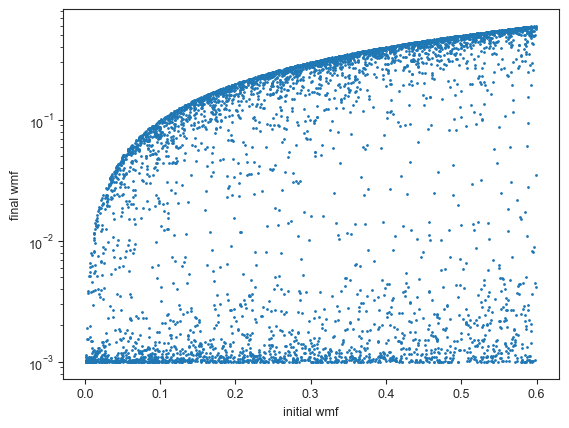

In [221]:
plt.scatter(wmf_gp,wmf_final,s=1)
plt.yscale('log')
plt.xlabel('initial wmf')
plt.ylabel('final wmf')

# We see clear distinction between planets keeping wmf and losing wmf

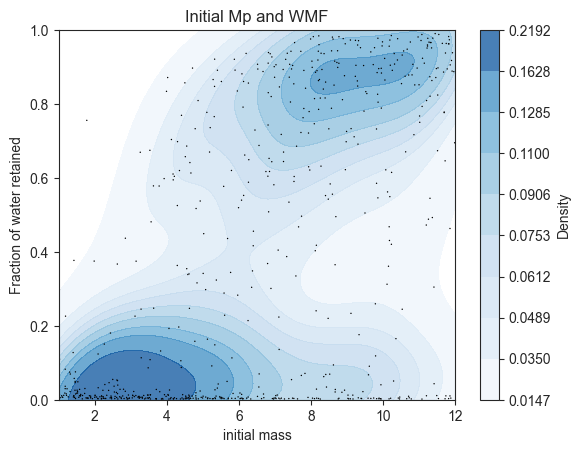

In [111]:
plt.scatter(mp_gp/M_e,wmf_final/wmf_gp, s=1, color='black', edgecolor='none')
plt.xlabel('initial mass')
plt.ylabel('Fraction of water retained')
plt.title('Initial Mp and WMF')
sns.kdeplot(x=mp_gp/M_e,y=wmf_final/wmf_gp,fill=True,cmap='Blues',alpha=0.75,zorder=-100,cbar=True,cbar_kws={'label':'Density'})
plt.xlim(1,12)
plt.ylim(0,1)
# plt.savefig(location+'/kde_mp_wmf_'+identifier+'.png',dpi=600)
plt.show()

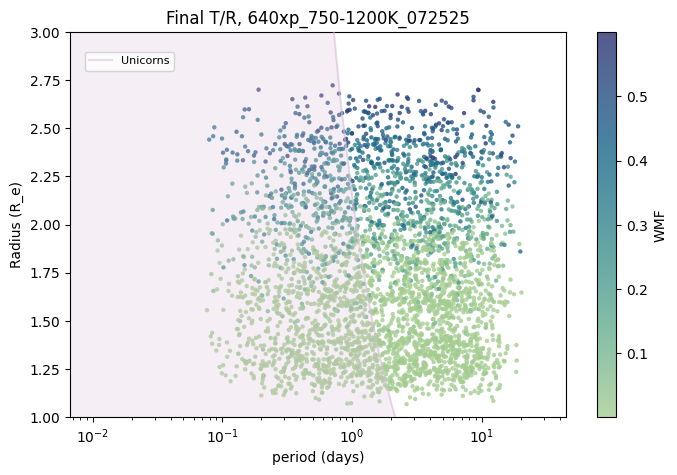

In [53]:
#- final T/R, coded ------------
MG_period = np.append(T_M,T_G)
MG_rp = np.append(Rp_M, Rp_G)
MG_lambda = np.append(lambda_gp[~startype_gp],lambda_gp[startype_gp])
MG_teq = np.append(teq_gp[~startype_gp],teq_gp[startype_gp])
MG_wmf_final = np.append(wmf_final[~startype_gp],wmf_final[startype_gp])
plt.figure(figsize=(8,5))

# #- M_star
# cmap_scale = 'mstar_'
# plt.scatter(period_gp, rp_final/R_e, c=mstar_gp/M_sun, cmap='inferno', s=15, edgecolor='none', alpha=0.75)
# plt.colorbar(label='M* (Solar Masses)')

#- WMF
cmap_scale = 'wmf_'
cmap = sns.color_palette('crest', as_cmap=True)
plt.scatter(period_gp, rp_final, c=wmf_final, cmap=cmap, edgecolor='none', s=10, alpha=0.8)
plt.colorbar(label='WMF')

# #- Jean's escape
# cmap_scale = 'lambda_'
# plt.scatter(MG_period, MG_rp, c=MG_lambda, cmap='plasma',edgecolor='none', s=10, alpha=.5)
# plt.colorbar(label='Λ (Jeans Escape Parameter)')

# #- Equilibrium temperature
# cmap_scale = 'Teq_'
# plt.scatter(T_G, Rp_G, c=MG_teq, cmap='inferno',edgecolor='none', s=10, alpha=1)
# plt.colorbar(label='K (Equilibrium Temperature)')


#unicorns line
# plt.axvspan(1,0,color='thistle',alpha=0.15,zorder=-500)
# plt.axvline(1,c='thistle',linewidth=1,label='Unicorns',alpha=.5,zorder=500)
plt.plot(x,roche_lim,label='Unicorns',color='thistle',alpha=.5,zorder=500)
plt.fill_betweenx(roche_lim,[0],x,color='thistle',alpha=0.25)

plt.ylim(1,3)

# plt.colorbar()
plt.xlabel('period (days)')
plt.xscale('log')
plt.ylabel('Radius (R_e)')
plt.title('Final T/R, '+identifier)
plt.legend(loc=(.03,.9),fontsize=8)

plt.savefig(location+'/scatter_tr_final_'+cmap_scale+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()

**My interpretation of the above plot:** (NOT VALID FOR CURRENT PLOT)

My model illustrates that most planets that are filling in the 1.8 Re radius gap have lost their entire water reservoir. I have planets that fill in the 1.8 radius gap-- while there is a clear split (around 10 days, and 2 radii), this still is more 'filled in' than what we've observed. 

I assume this is because this model is for pure steam/water/etc. Most observed planets are *not* pure steam, and probably more hycean. Steam atmospheres, when extended, are smaller than H/He; if this was real data, this would be result in:
1. overprediction of WMF,
2. overprediction of radius (for a given mass)
3. high radius that's attributed to the core/mantle, when observed data may be showing planets that have atmospheres more extended than just H2O

Updated note: For a range of planets that span 7-12 Me, we can expect that for planets exhausted of their water, the radii of their cores may fall in this 1.4-2 Re and artificially fill in this gap.

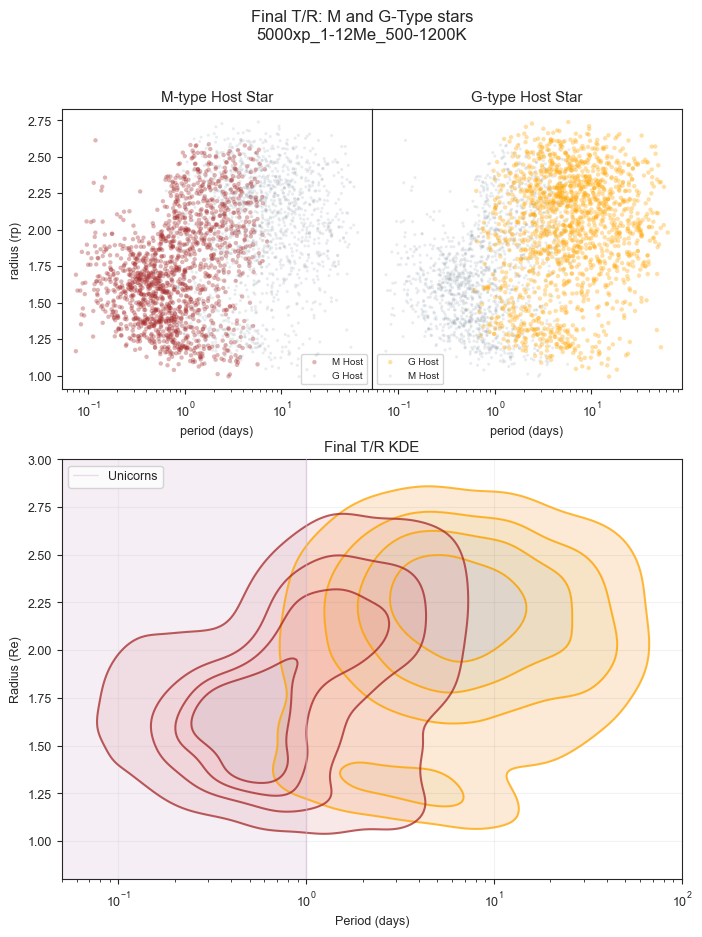

In [212]:
# plt.scatter(period_gp,rp_final,c=wmf_final,alpha=0.15,zorder=200,label='Final WMF') #edgecolors='none',
# fig, ax = plt.subplots(1,2, figsize=(8,4))
endrange = 1500 # 1500

fig = plt.figure(figsize=(8,10))
plt.rcParams.update({'font.size': 9})
gs = fig.add_gridspec(2,2,height_ratios=[2,3])
ax0 = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])
ax2 = fig.add_subplot(gs[1,:])

fig.subplots_adjust(hspace=0.2, wspace=0)
fig.suptitle('Final T/R: M and G-Type stars\n'+identifier,fontsize=12)


ax0.scatter(T_M[0:endrange], Rp_M[0:endrange], color='brown', s=10, edgecolor='none', alpha=0.35, zorder=200, label='M Host')
ax0.scatter(T_G[0:endrange], Rp_G[0:endrange], color='slategrey', s=5, edgecolor='none', alpha=0.15, zorder=100, label='G Host') #facecolor='none', edgecolor='brown', 
# sns.kdeplot(x=period_gp,y=rp_gp,label='Initial') #https://ui.adsabs.harvard.edu/abs/2017AJ....154..109F/abstract
ax0.set(xlabel='period (days)', ylabel='radius (rp)', xscale='log')#xlim=(0,57))
# ax0.grid(color='slategrey',alpha=0.25)
ax0.legend(loc='lower right', fontsize=7)
ax0.set_title('M-type Host Star')

ax1.scatter(T_G[0:endrange], Rp_G[0:endrange], color='orange', s=10, edgecolor='none', alpha=0.35, zorder=200, label='G Host')
ax1.scatter(T_M[0:endrange], Rp_M[0:endrange], color='slategrey', s=5, edgecolor='none', alpha=0.15, zorder=100, label='M Host') #facecolor='none', edgecolor='brown', 
# sns.kdeplot(x=period_gp,y=rp_gp,label='Initial') #https://ui.adsabs.harvard.edu/abs/2017AJ....154..109F/abstract
ax1.set(xlabel='period (days)', xscale='log')
ax1.tick_params('y', labelleft=False)
ax1.set_yticks([])
#, xlim=(0,57))#xscale='log')
# ax1.grid(color='slategrey',alpha=0.25)
ax1.legend(fontsize=7)
ax1.set_title('G-type Host Star')



# alternatively

# figure = plt.figure(figsize=(8,6))
sns.kdeplot(x=T_M, y=Rp_M, color='brown', levels=5, log_scale=True, alpha=0.75, zorder=5)
sns.kdeplot(x=T_G, y=Rp_G, color='orange', levels=5, log_scale=True, alpha=0.75)
sns.kdeplot(x=T_M, y=Rp_M, color='brown', fill=True, levels=5, log_scale=True, alpha=0.25, zorder=-1)
sns.kdeplot(x=T_G, y=Rp_G, color='orange', fill=True, levels=5, log_scale=True, alpha=0.25, zorder=-5)
ax2.grid(color='slategrey', alpha=0.1)
ax2.set(xlim=[0.05,100], ylim=[0.8,3], yscale='linear',xlabel='Period (days)', ylabel='Radius (Re)')
ax2.set_title('Final T/R KDE')


#unicorns line
ax2.axvspan(0.001,1,color='thistle',alpha=0.25)
ax2.axvline(1,c='thistle',linewidth=1,label='Unicorns',alpha=.5,zorder=500)
ax2.legend(loc='upper left')

# plt.savefig(location+'/composite_tr_final_startype_'+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()


M-hosts: 555
G-hosts: 945


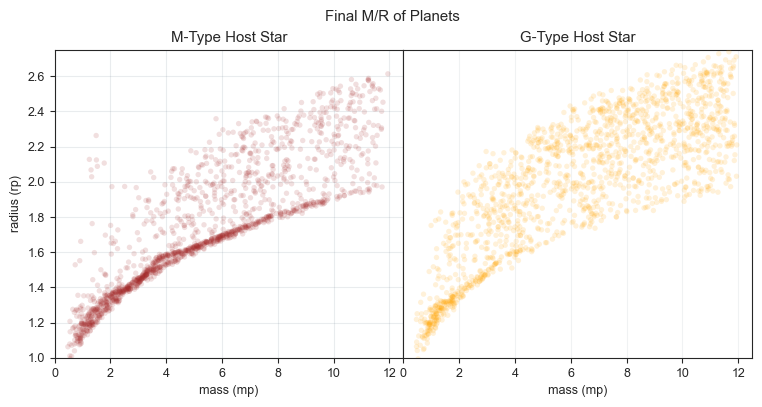

In [213]:
# M/R scatterplot
# plt.scatter(mp_final,rp_final,c=wmf_gp,alpha=0.15,zorder=200) #wmf
# size = (mp_gp[0:800]**4)/400 #dependent on initial masses
# plt.scatter(mp_final[0:800],rp_final[0:800],s=size,alpha=0.25, c=mstar_gp[0:800], cmap='inferno', zorder=200)

fig, ax = plt.subplots(1,2, figsize=(9,4))
plt.subplots_adjust(wspace=0)

#shuffle arrays
size = (mp_gp**2)/5 #dependent on initial masses
mp_M = mp_final[~startype_gp]
rp_M = rp_final[~startype_gp]
size_M = size[~startype_gp]
mstar_M = mstar_gp[~startype_gp]

mp_G = mp_final[startype_gp]
rp_G = rp_final[startype_gp]
size_G = size[startype_gp]
mstar_G = mstar_gp[startype_gp]

ax[0].scatter(mp_M[0:endrange]/M_e,rp_M[0:endrange]/R_e,s=15, color='brown',edgecolor='none',alpha=0.15, zorder=200)
# ax[0].scatter(mp_M, rp_M, s=size_M[0:len(rp_M)], alpha=1, c=mstar_M, cmap='Reds', zorder=200)
ax[0].grid(color='slategrey',alpha=0.15)
ax[0].set(xlabel='mass (mp)',ylabel='radius (rp)', title='M-Type Host Star')
ax[0].set(xlim=(0,12.5), ylim=(1,2.75))


ax[1].scatter(mp_G[0:endrange]/M_e,rp_G[0:endrange]/R_e,s=15, color='orange',edgecolor='none', alpha=0.15, zorder=200)
# ax[1].scatter(mp_G, rp_G, s=size_G[0:1500], alpha=1, c=mstar_G, cmap='YlOrRd_r', zorder=200)
ax[1].grid(color='slategrey',alpha=0.1)
ax[1].set(xlabel='mass (mp)', title='G-Type Host Star')
ax[1].set(xlim=(0,12.5), ylim=(1,2.75))
ax[1].tick_params('y', labelleft=False)
ax[1].set_yticks([])
fig.suptitle('Final M/R of Planets')

x = mp_final[0:endrange]
xx = x[startype_gp[0:endrange]<=0]
yy = x[startype_gp[0:endrange]>0]
print(f'M-hosts: {len(xx)}\nG-hosts: {len(yy)}')

# plt.savefig(location+'/scatter_mr_final_startype_'+identifier+'.png',bbox_inches='tight',dpi=600)
plt.show()

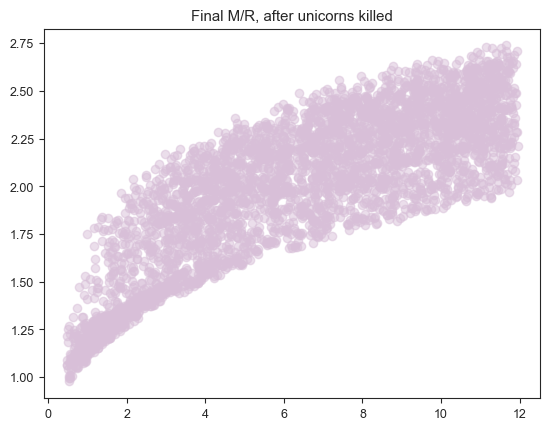

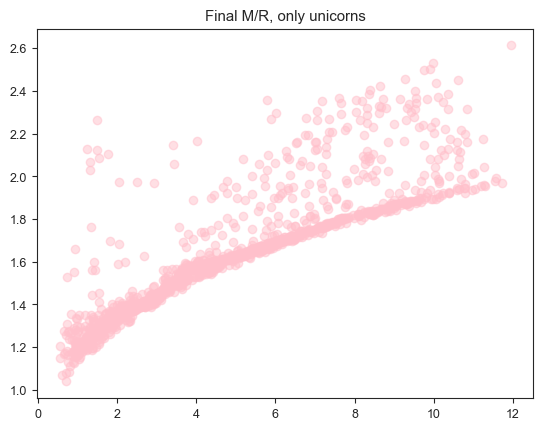

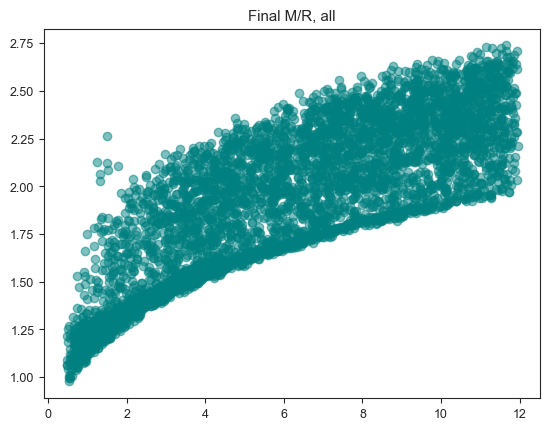

In [214]:
plt.scatter(mp_final[unicorn_killer]/M_e, rp_final[unicorn_killer]/R_e, c='thistle',alpha=.5)
plt.title('Final M/R, after unicorns killed')
plt.show()
plt.clf()

unicorns = period_gp < 1
plt.scatter(mp_final[unicorns]/M_e, rp_final[unicorns]/R_e, c='pink', alpha=.5)
plt.title('Final M/R, only unicorns')
plt.show()
plt.clf()

plt.scatter(mp_final/M_e, rp_final/R_e, c='teal', alpha=.5)
plt.title('Final M/R, all')
plt.show()

In [215]:
print('Unicorns:', len(planetnum[unicorns]), '-', n_planets, 'Planets')

Unicorns: 1204 - 5000 Planets
